# 01 - Exploratory Data Analysis
Dataset: UCI Heart Disease (Cleveland clinic subset). The label `target` is 1 when angiographic disease is present and 0 when it is not.

In [1]:
import sys
sys.path.append('..')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from src import data
sns.set_theme(style='ticks', context='notebook', palette=['#2a9d8f', '#e76f51'])
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
%matplotlib inline

## 1. Load and inspect

In [2]:
raw = data.load_raw(data.download())
print(raw.shape)
print('Columns with missing values:'); print(raw.isna().sum()[raw.isna().sum() > 0])
raw.head()

(303, 14)
Columns with missing values:
ca      4
thal    2
dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
df = data.clean(raw)
data.save_clean(df)
print(df.shape, 'duplicates removed:', len(raw) - len(df))
df.describe().T

(303, 14) duplicates removed: 0


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


Only two columns have gaps: `ca` (4 rows) and `thal` (2 rows). Both are discrete codes, so the most frequent value is a safer fill than a mean.

## 2. Class balance

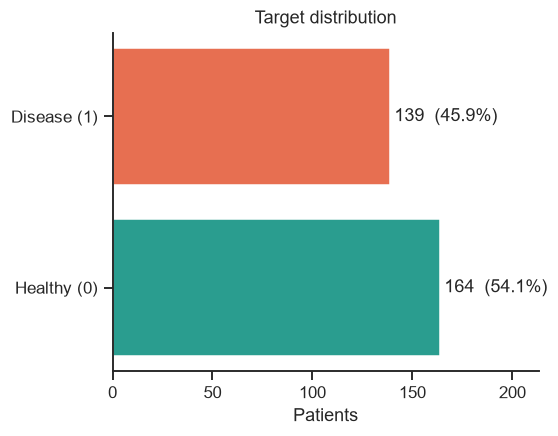

In [4]:
counts = df['target'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 4))
ax.barh(['Healthy (0)', 'Disease (1)'], counts.values, color=['#2a9d8f', '#e76f51'])
for i, v in enumerate(counts.values):
    ax.text(v + 2, i, f'{v}  ({v/len(df):.1%})', va='center')
ax.set_xlabel('Patients'); ax.set_title('Target distribution'); ax.set_xlim(0, counts.max() * 1.3)
plt.savefig('../screenshots/eda_class_balance.png', dpi=150, bbox_inches='tight'); plt.show()

The split is close to even, with slightly more healthy patients. That means plain accuracy is a fair headline number and I do not need oversampling or class weights.

## 3. Numeric feature distributions

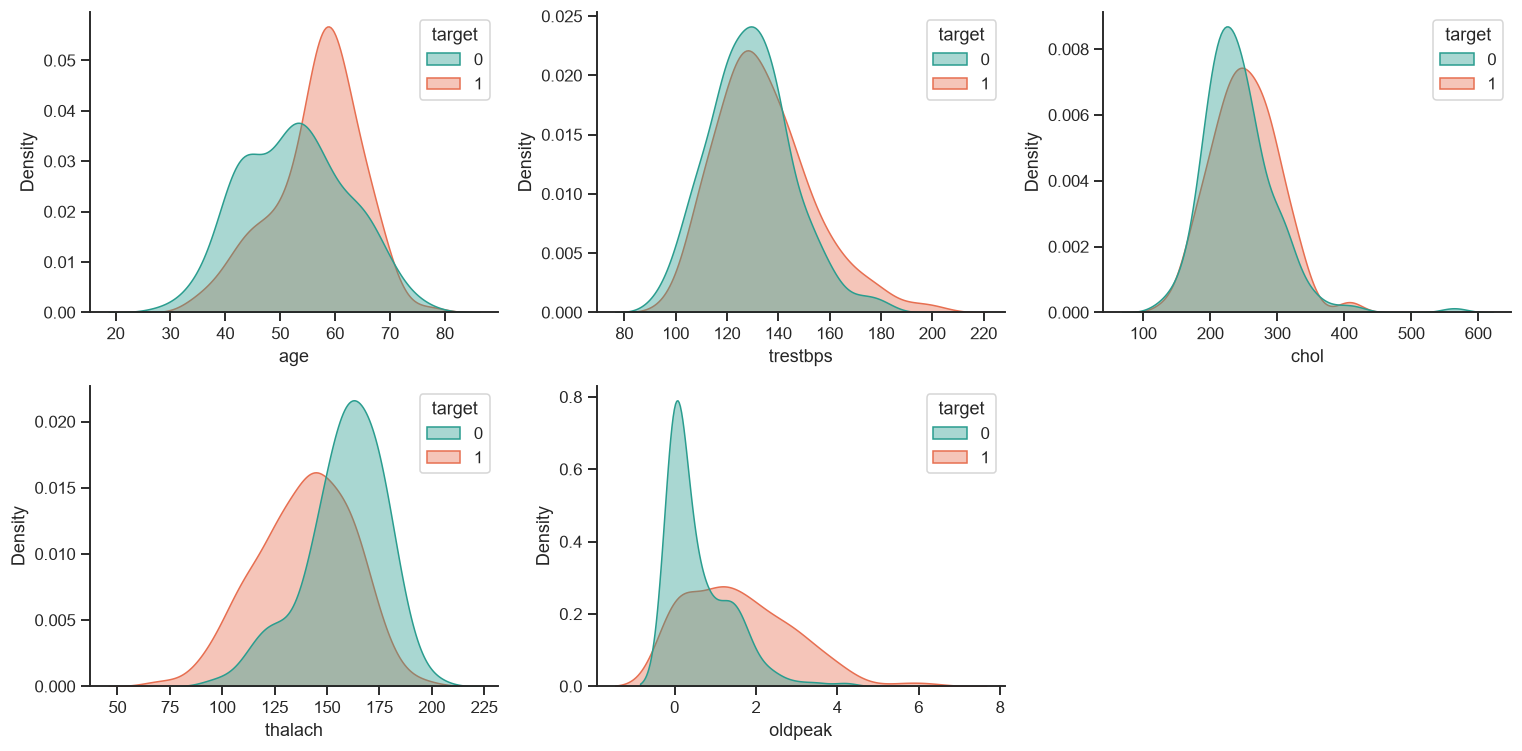

In [5]:
num = data.NUMERIC
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), num):
    sns.kdeplot(data=df, x=c, hue='target', fill=True, common_norm=False, alpha=0.4, ax=ax)
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.savefig('../screenshots/eda_histograms.png', dpi=150); plt.show()

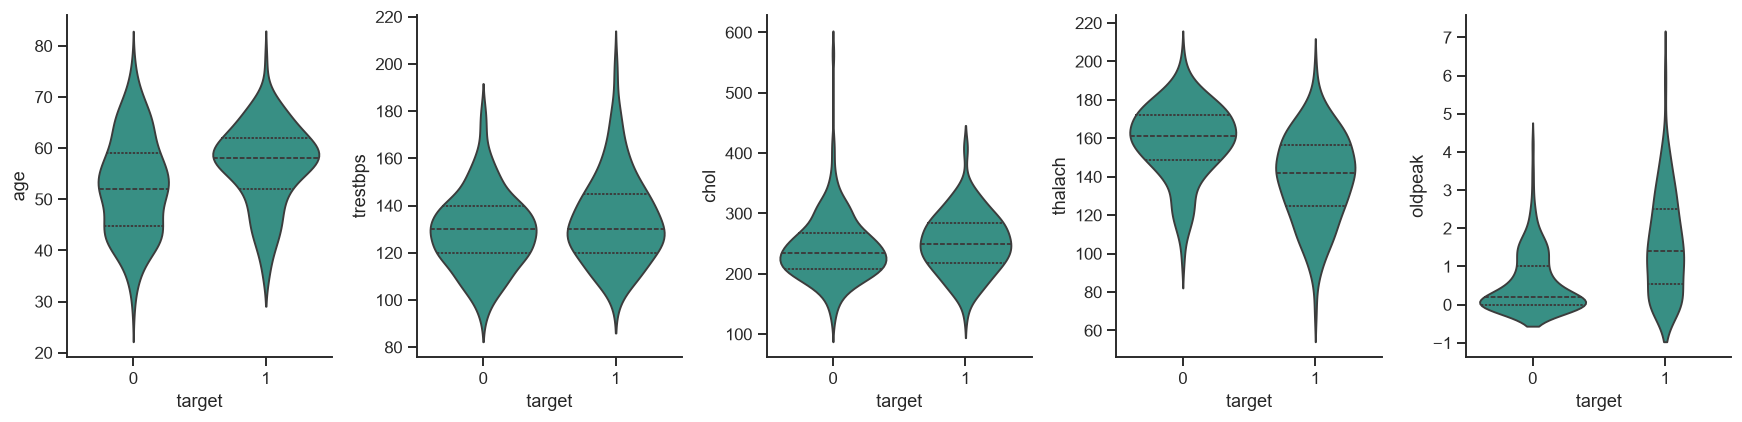

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, c in zip(axes, num):
    sns.violinplot(data=df, x='target', y=c, ax=ax, inner='quartile')
plt.tight_layout(); plt.savefig('../screenshots/eda_boxplots.png', dpi=150); plt.show()

Sick patients cluster at a lower peak heart rate (`thalach`) and at higher ST depression (`oldpeak`), so those two separate the classes best among the numeric columns. Cholesterol and resting blood pressure look almost identical for both groups, with a few extreme values on the high side.

## 4. Age bands vs disease rate (my own addition)

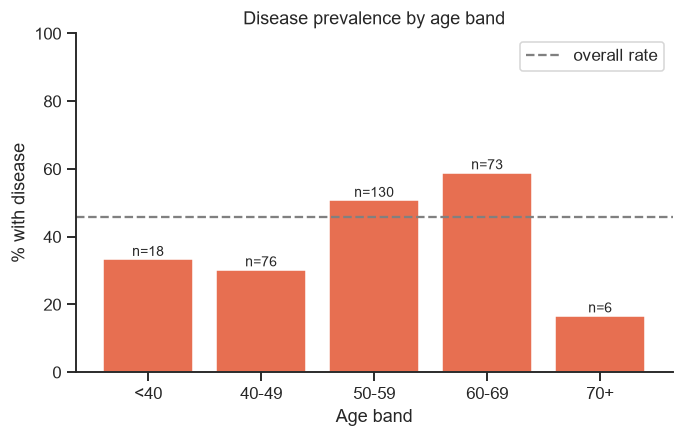

In [7]:
df['age_band'] = pd.cut(df['age'], bins=[28, 40, 50, 60, 70, 80], labels=['<40', '40-49', '50-59', '60-69', '70+'])
rate = df.groupby('age_band', observed=True)['target'].agg(['mean', 'count'])
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(rate.index.astype(str), rate['mean'] * 100, color='#e76f51')
for b, n in zip(bars, rate['count']):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f'n={n}', ha='center', fontsize=9)
ax.axhline(df['target'].mean() * 100, ls='--', color='grey', label='overall rate')
ax.set_ylabel('% with disease'); ax.set_xlabel('Age band'); ax.set_ylim(0, 100); ax.legend()
ax.set_title('Disease prevalence by age band')
plt.savefig('../screenshots/eda_age_bands.png', dpi=150, bbox_inches='tight'); plt.show()
df = df.drop(columns='age_band')

Prevalence rises with age, but it is not a clean line: the 40s band is below the overall rate while the 50s and 60s sit above it. The oldest band has few patients, so I read it cautiously. Age helps, but it is a weaker signal than the clinical measurements.

## 5. Categorical features vs target

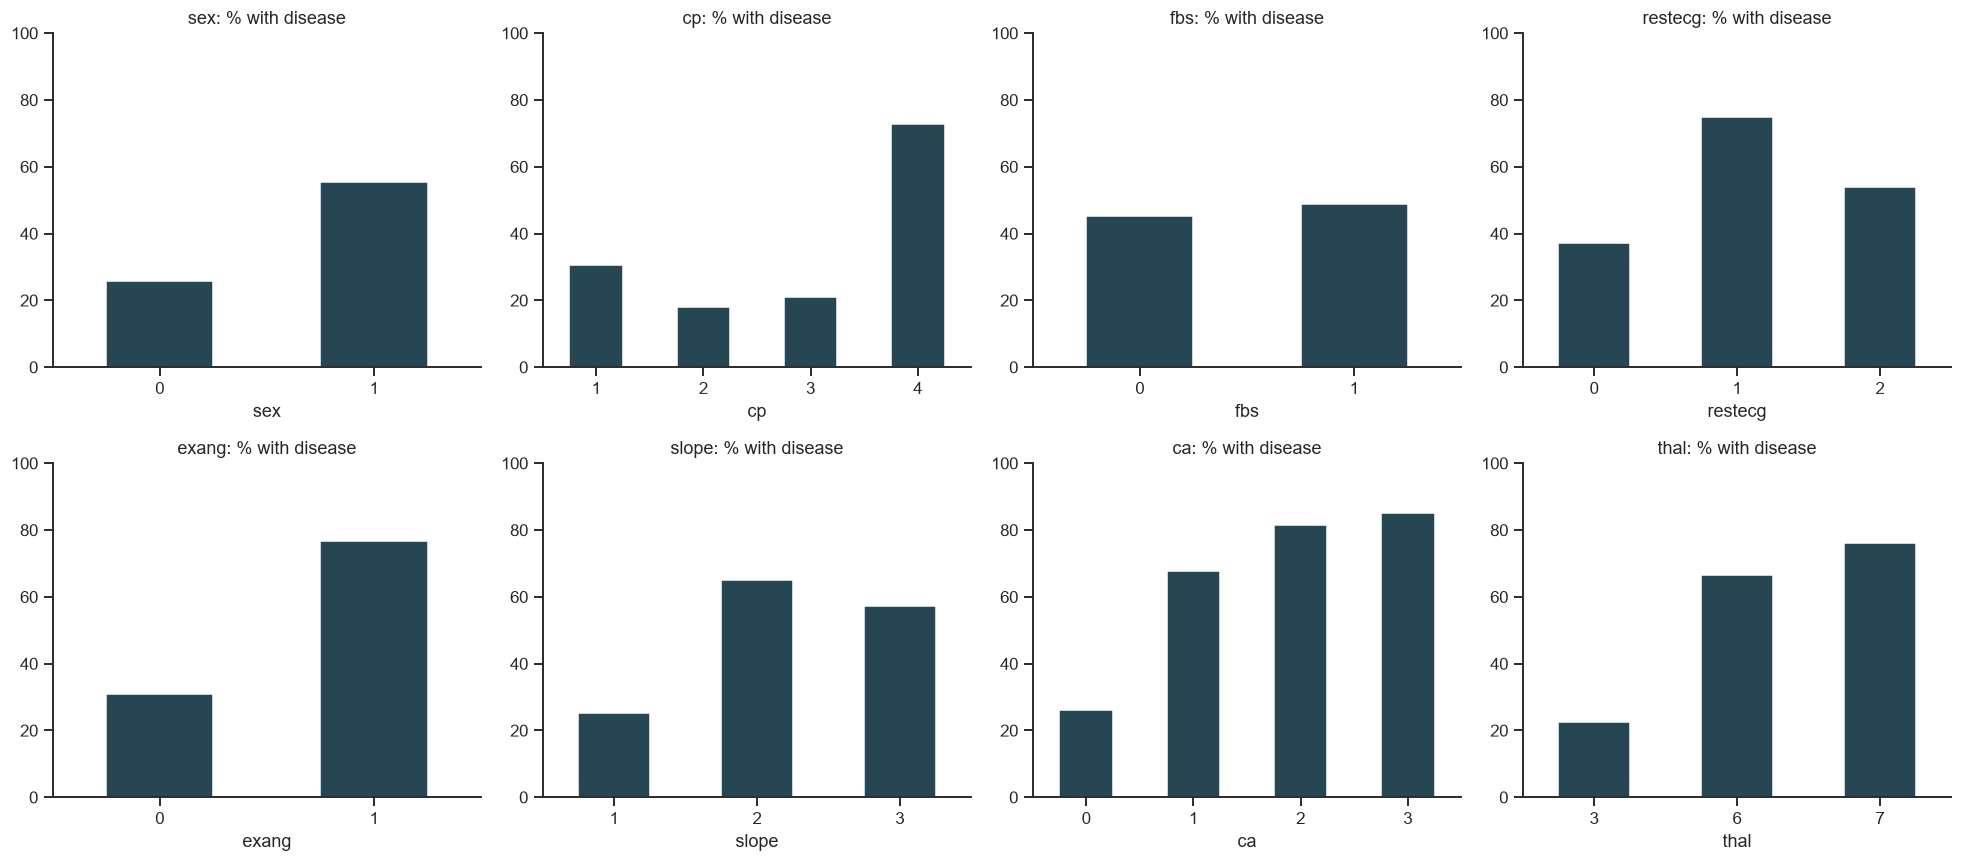

In [8]:
cats = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), cats):
    (df.groupby(c)['target'].mean() * 100).plot(kind='bar', ax=ax, color='#264653')
    ax.set_title(f'{c}: % with disease'); ax.set_ylim(0, 100); ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.savefig('../screenshots/eda_categorical.png', dpi=150); plt.show()

Disease rates jump for asymptomatic chest pain (`cp` = 4), exercise-induced angina, a reversible defect on the thallium scan (`thal` = 7) and any blocked major vessel (`ca` >= 1). `fbs` barely moves the rate, which agrees with its near-zero correlation.

## 6. Correlation heatmap

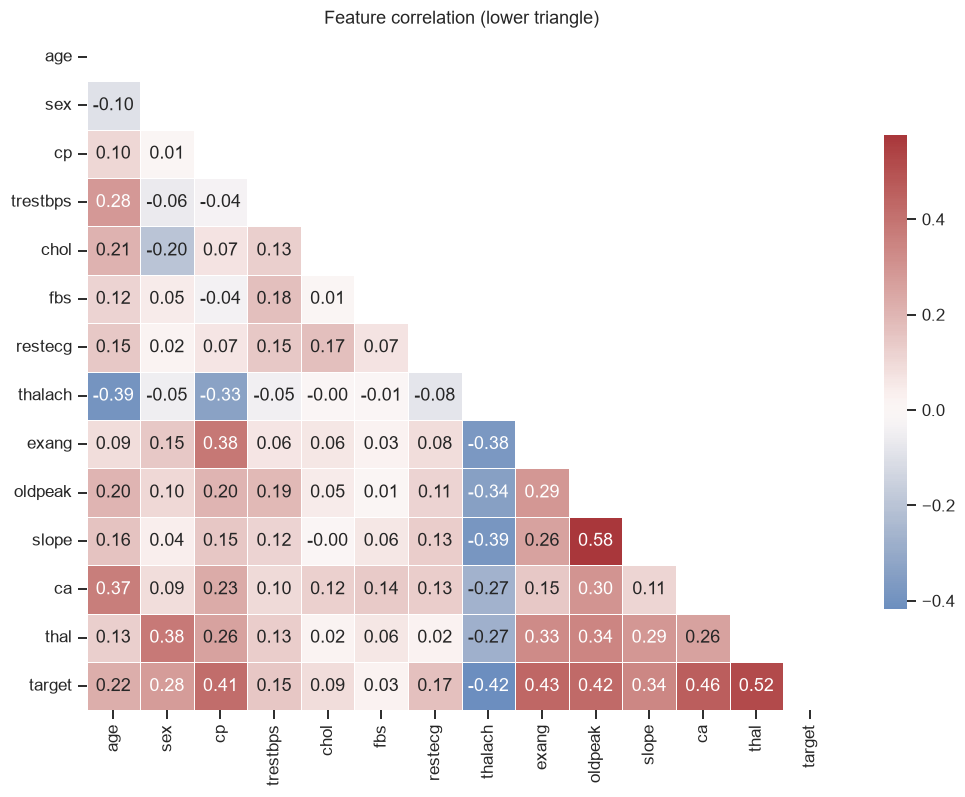

thal        0.52
ca          0.46
exang       0.43
oldpeak     0.42
thalach     0.42
cp          0.41
slope       0.34
sex         0.28
age         0.22
restecg     0.17
trestbps    0.15
chol        0.09
fbs         0.03
Name: target, dtype: float64

In [9]:
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(11, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='vlag', center=0, linewidths=.5, cbar_kws={'shrink': .7})
plt.title('Feature correlation (lower triangle)'); plt.savefig('../screenshots/eda_correlation.png', dpi=150, bbox_inches='tight'); plt.show()
corr['target'].drop('target').abs().sort_values(ascending=False).round(2)

`thal`, `ca`, `exang`, `oldpeak`, `thalach` and `cp` have the strongest link to the target (about 0.4-0.5 in absolute value). No two features are strongly collinear, so I keep all 13 and let the models and regularisation decide what matters.

## 7. Take-aways for modelling
- 303 rows, 13 features, nearly balanced binary target; 6 values imputed.
- Numeric columns live on different scales, so they get standardised; the discrete clinical codes get one-hot encoded.
- Recall matters most here (a missed patient is the costly error), so I will track recall alongside ROC-AUC rather than accuracy alone.